In [5]:
%load_ext autoreload
%autoreload 2

import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import balanced_accuracy_score, classification_report

from utils import (AZUL, CINZA, LARANJA, RAIZ, RESULTADOS, TINTA, TINTA_2, carrega_dados, estilo,
                   plota_confusao, remove_duplicadas)

pd.set_option("display.max_columns", 200)
estilo()
print(f"Python {sys.version.split()[0]} | {platform.platform()}")
for lib in (np, pd, sklearn, matplotlib):
    print(f"{lib.__name__:<12}{lib.__version__}")

CLASSES = np.arange(1, 9)
NOME_FINAL = "E15-r01-stack_5seeds"
NOME_ANTERIOR = "E08-r01-hgb-busca+kw_soma"  # modelo único, referência de comparação

treino, teste = carrega_dados()          # confere os hashes de train, test e folds
treino = remove_duplicadas(treino)
y = treino["Response"].to_numpy()
fold = treino["fold"].to_numpy()

runs = pd.read_csv(RESULTADOS / "runs.csv").set_index("run")
registro = pd.read_csv(RAIZ / "submissoes" / "registro.csv").set_index("run")


def oof_do_run(nome):
    """Probabilidades OOF de um run registrado, na ordem do treino."""
    oof = pd.read_csv(RESULTADOS / "oof" / f"{nome}__{runs.loc[nome, 'config_hash']}.csv.gz")
    assert (oof["Id"].to_numpy() == treino["Id"].to_numpy()).all(), "OOF fora da ordem do treino"
    return oof[[f"p{c}" for c in CLASSES]].to_numpy()


meta = {"run": NOME_FINAL, "config_hash": runs.loc[NOME_FINAL, "config_hash"],
        "config": json.loads(runs.loc[NOME_FINAL, "config"]),
        "cv_bal_acc": float(runs.loc[NOME_FINAL, "bal_acc_media"]),
        "kaggle_publico": float(registro.loc[NOME_FINAL, "kaggle_publico"])}
assert meta["config_hash"] == registro.loc[NOME_FINAL, "config_hash"], "run registrado diferente do submetido"

P = oof_do_run(NOME_FINAL)                # probabilidades OOF do modelo final
pred = CLASSES[P.argmax(axis=1)]          # classe prevista OOF
P_ant = oof_do_run(NOME_ANTERIOR)
pred_ant = CLASSES[P_ant.argmax(axis=1)]

print(meta["run"], "| CV registrada:", round(meta["cv_bal_acc"], 4), "| Kaggle:", meta["kaggle_publico"])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python 3.12.12 | macOS-26.5.1-arm64-arm-64bit
numpy       2.5.5
pandas      3.1.1
sklearn     1.9.1
matplotlib  3.11.2
E15-r01-stack_5seeds | CV registrada: 0.5402 | Kaggle: 0.54377


In [8]:
por_fold = pd.Series([balanced_accuracy_score(y[fold == k], pred[fold == k]) for k in range(5)],
                     index=[f"fold {k}" for k in range(5)], name="balanced accuracy")
print(por_fold.round(4).to_dict())
print(f"média CV: {por_fold.mean():.4f} (registrada: {meta['cv_bal_acc']:.4f}) | Kaggle: {meta['kaggle_publico']}")

{'fold 0': 0.5373, 'fold 1': 0.5376, 'fold 2': 0.5305, 'fold 3': 0.5396, 'fold 4': 0.556}
média CV: 0.5402 (registrada: 0.5402) | Kaggle: 0.54377


In [9]:
rel = pd.DataFrame(classification_report(y, pred, labels=CLASSES, output_dict=True)).T
por_classe = rel.loc[[str(c) for c in CLASSES], ["precision", "recall", "f1-score", "support"]]
por_classe.index = CLASSES
por_classe["support"] = por_classe["support"].astype(int)
por_classe.round(3)

,precision,recall,f1-score,support
1,0.373,0.312,0.340,4906
2,0.409,0.300,0.346,5242
3,0.455,0.558,0.502,806
4,0.496,0.719,0.587,1144
5,0.556,0.601,0.578,4312
6,0.587,0.434,0.499,8981
7,0.421,0.608,0.497,6468
8,0.758,0.789,0.773,15628


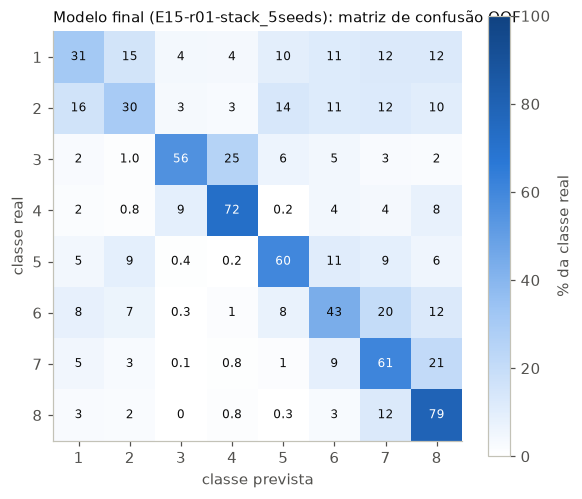

In [7]:
cm_final = plota_confusao(y, pred, f"Modelo final ({meta['run']}): matriz de confusão OOF")

In [10]:
rel_ant = pd.DataFrame(classification_report(y, pred_ant, labels=CLASSES, output_dict=True)).T
linhas = [str(c) for c in CLASSES]
comparacao = pd.DataFrame({
    "recall E08": rel_ant.loc[linhas, "recall"].to_numpy(),
    "recall final": por_classe["recall"].to_numpy(),
    "precisão E08": rel_ant.loc[linhas, "precision"].to_numpy(),
    "precisão final": por_classe["precision"].to_numpy(),
    "previstos E08": np.bincount(pred_ant, minlength=9)[1:],
    "previstos final": np.bincount(pred, minlength=9)[1:],
}, index=CLASSES)
comparacao.insert(2, "Δ recall", comparacao["recall final"] - comparacao["recall E08"])

mudou = pred != pred_ant
print(f"previsões que mudaram: {mudou.mean():.1%} ({mudou.sum()} linhas)")
print(f"  passaram a acertar: {(mudou & (pred == y)).sum()} | passaram a errar: {(mudou & (pred_ant == y)).sum()} "
      f"| erradas nos dois: {(mudou & (pred != y) & (pred_ant != y)).sum()}")
comparacao.round(3)

previsões que mudaram: 10.3% (4881 linhas)
  passaram a acertar: 1477 | passaram a errar: 1660 | erradas nos dois: 1744


,recall E08,recall final,Δ recall,precisão E08,precisão final,previstos E08,previstos final
1,0.301,0.312,0.011,0.380,0.373,3891,4102
2,0.286,0.300,0.014,0.413,0.409,3633,3837
3,0.531,0.558,0.027,0.480,0.455,892,988
4,0.713,0.719,0.006,0.574,0.496,1421,1659
5,0.595,0.601,0.006,0.562,0.556,4563,4658
6,0.440,0.434,-0.006,0.582,0.587,6790,6630
7,0.596,0.608,0.012,0.419,0.421,9188,9340
8,0.814,0.789,-0.025,0.743,0.758,17109,16273
